In [1]:
# 한글 폰트
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 38.7 MB/s eta 0:00:00


In [7]:
# ============================================================
# 13주차 과제 — 통합 정답 코드
# week13_health.csv 분석
# ============================================================

# ─── 0. 라이브러리 및 데이터 로드 ───
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

df = pd.read_csv('week13_health.csv', encoding='cp949')
print(f"데이터 shape: {df.shape}")
print(df.head())

데이터 shape: (250, 10)
   환자ID  나이 성별 흡연   운동   BMI   혈압   혈당  콜레스테롤  진단
0  H001  41  남  N  2.0  23.9  105   97    185  건강
1  H002  52  여  N  0.0  24.3  117  106    222  주의
2  H003  30  남  N  1.0  19.0  112   74    166  건강
3  H004  65  여  N  4.0  20.8  114   89    258  건강
4  H005  57  여  Y  4.0  23.7  123   82    218  주의


In [8]:
# ─── Q1. 정규성 진단 ───
print("="*60)
print("[Q1] 콜레스테롤 정규성 진단")
print("="*60)

x = df['콜레스테롤']

# 정량 진단
print(f"왜도 = {x.skew():.4f}")
stat, p = stats.shapiro(x)
print(f"Shapiro 통계량 = {stat:.4f}")
print(f"Shapiro p-value = {p:.4e}")
print(f"→ p < 0.05  ⇒  정규성 위배")
# 정답: ① 왜도 ≈ 0.77, p < 0.001 → 정규성 위배

[Q1] 콜레스테롤 정규성 진단
왜도 = 0.7730
Shapiro 통계량 = 0.9544
Shapiro p-value = 4.4551e-07
→ p < 0.05  ⇒  정규성 위배


In [9]:
# ─── Q2. 변환 효과 비교 ───
print("="*60)
print("[Q2] 변환별 정규성 효과 비교")
print("="*60)

x_log = np.log1p(x)              # 로그 변환
x_sqrt = np.sqrt(x)              # 제곱근 변환
x_bc, lam = stats.boxcox(x)      # Box-Cox 변환

results = []
for name, data in [('원본', x), ('로그', x_log), ('제곱근', x_sqrt),
                   (f'Box-Cox (λ={lam:.3f})', x_bc)]:
    sk = pd.Series(data).skew()
    _, pv = stats.shapiro(data)
    results.append({'변환': name, '왜도': round(sk, 4), 'Shapiro p': f'{pv:.4e}'})

pd.set_option('display.colheader_justify', 'left')
print(pd.DataFrame(results).to_string(index=False, col_space=15, justify='left'))
# 정답: ③ Box-Cox 변환 (λ ≈ -0.49, 왜도 ≈ -0.02)

[Q2] 변환별 정규성 효과 비교
변환                  왜도             Shapiro p      
                원본  0.7730         4.4551e-07     
                로그  0.2184         3.3925e-04     
               제곱근  0.4793         2.0811e-05     
Box-Cox (λ=-0.494) -0.0186         1.3545e-03     


In [10]:
# ─── Q3-Q4. 독립표본 t-test ───
print("="*60)
print("[Q3-Q4] 흡연 vs 비흡연 혈압 t-test")
print("="*60)

yes = df[df['흡연']=='Y']['혈압']
no = df[df['흡연']=='N']['혈압']

print(f"흡연자  평균 = {yes.mean():.2f} mmHg  (n={len(yes)})")
print(f"비흡연자 평균 = {no.mean():.2f} mmHg  (n={len(no)})")
print(f"평균 차이 = {yes.mean() - no.mean():+.2f} mmHg")

# Levene 등분산 검정
lev_stat, lev_p = stats.levene(yes, no)
print(f"\nLevene 검정: stat={lev_stat:.3f}, p={lev_p:.4f}")

# 등분산 여부에 따라 t-test 선택
if lev_p > 0.05:
    print("→ p > 0.05: 등분산 가정 가능 → equal_var=True")
    equal_var = True
else:
    print("→ p < 0.05: 등분산 가정 불가 → Welch's t-test")
    equal_var = False

t, p = stats.ttest_ind(yes, no, equal_var=equal_var)
print(f"\nt = {t:.3f}, p = {p:.4e}")

# 정답:
# Q3: ② 약 +11 mmHg, p < 0.001 → 통계적으로 유의함
# Q4: ① Levene p > 0.05 → 등분산 가정 t-test (equal_var=True)

[Q3-Q4] 흡연 vs 비흡연 혈압 t-test
흡연자  평균 = 127.18 mmHg  (n=51)
비흡연자 평균 = 116.30 mmHg  (n=199)
평균 차이 = +10.88 mmHg

Levene 검정: stat=0.069, p=0.7927
→ p > 0.05: 등분산 가정 가능 → equal_var=True

t = 6.129, p = 3.4619e-09


In [ ]:
# ─── Q5. 일원분산분석 ───
print("="*60)
print("[Q5] ANOVA — 진단별 BMI")
print("="*60)

# 그룹별 평균 확인
print(df.groupby('진단')['BMI'].agg(['mean','count']).round(3))

# ANOVA
groups = [df[df['진단']==g]['BMI'] for g in ['건강', '주의', '위험']]
f_stat, p = stats.f_oneway(*groups)
print(f"\nF = {f_stat:.3f}, p = {p:.4e}")
# 정답: ③ F ≈ 92.7, p < 0.001

[Q5] ANOVA — 진단별 BMI
    mean    count
진단               
건강  22.316   81  
위험  28.325   36  
주의  25.398  133  

F = 92.681, p = 9.3505e-31


In [ ]:
# ─── Q6. Tukey HSD 사후검정 ───
print("="*60)
print("[Q6] Tukey HSD 사후검정")
print("="*60)

result = pairwise_tukeyhsd(endog=df['BMI'], groups=df['진단'], alpha=0.05)
print(result)

# reject=True인 쌍 개수
n_significant = sum(result.reject)
print(f"\n통계적으로 유의한 쌍의 개수: {n_significant}쌍")
# 정답: ④ 3쌍 모두 유의 — 건강 < 주의 < 위험 순서로 모두 다름

[Q6] Tukey HSD 사후검정
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
    건강     위험    6.009   0.0  4.9149   7.103   True
    건강     주의   3.0824   0.0  2.3126  3.8523   True
    위험     주의  -2.9265   0.0 -3.9527 -1.9003   True
---------------------------------------------------

통계적으로 유의한 쌍의 개수: 3쌍


In [ ]:
# ─── Q7-Q8. 카이제곱 검정 ───
print("="*60)
print("[Q7-Q8] 성별 × 진단 카이제곱 검정")
print("="*60)

# 교차표 생성
ct = pd.crosstab(df['성별'], df['진단'])
print("관측 빈도:")
print(ct)

# 카이제곱 검정
chi2, p, dof, expected = stats.chi2_contingency(ct)

print(f"\nχ² = {chi2:.4f}")
print(f"p-value = {p:.4f}")
print(f"자유도 = {dof}")

print(f"\n기대 빈도:")
print(pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(2))

# 결론
print("\n[결론]")
if p < 0.05:
    print("p < 0.05 → 귀무가설 기각 → 성별과 진단은 연관이 있다")
else:
    print(f"p = {p:.4f} > 0.05 → 귀무가설 기각 불가")
    print("→ 성별과 진단의 연관성에 대한 통계적 증거 부족")
    print("  (독립이라고 단정할 수는 없음, 단지 증거 부족)")

# 정답:
# Q7: ① χ² ≈ 3.3, p ≈ 0.19 → α=0.05에서 유의하지 않음
# Q8: ③ p > 0.05이므로 귀무가설을 기각하지 못함 — 연관성 증거 부족

[Q7-Q8] 성별 × 진단 카이제곱 검정
관측 빈도:
진단  건강  위험  주의
성별            
남   36  22  72
여   45  14  61

χ² = 3.2928
p-value = 0.1927
자유도 = 2

기대 빈도:
진단  건강     위험     주의   
성별                     
남   42.12  18.72  69.16
여   38.88  17.28  63.84

[결론]
p = 0.1927 > 0.05 → 귀무가설 기각 불가
→ 성별과 진단의 연관성에 대한 통계적 증거 부족
  (독립이라고 단정할 수는 없음, 단지 증거 부족)


In [ ]:
# ─── Q9-Q10. 다중선형회귀 ───
model = smf.ols('콜레스테롤 ~ 나이 + BMI + 혈압', data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  콜레스테롤   R-squared:                       0.602
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                     124.1
Date:                Mon, 01 Jun 2026   Prob (F-statistic):           5.70e-49
Time:                        02:59:05   Log-Likelihood:                -1007.7
No. Observations:                 250   AIC:                             2023.
Df Residuals:                     246   BIC:                             2037.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     53.5736     10.825      4.949      0.0

In [ ]:
# 주요 수치만 정리
print("="*60)
print("[Q9] 모델 적합도")
print("="*60)
print(f"R²       = {model.rsquared:.4f}")
print(f"Adj. R²  = {model.rsquared_adj:.4f}")
print(f"F        = {model.fvalue:.3f}")
print(f"Prob(F)  = {model.f_pvalue:.4e}")
# 정답: ② R² ≈ 0.60, F = 124.1, p < 0.001

[Q9] 모델 적합도
R²       = 0.6021
Adj. R²  = 0.5973
F        = 124.104
Prob(F)  = 5.7044e-49


In [ ]:
print("="*60)
print("[Q10] 회귀계수 해석")
print("="*60)

# 계수 + p-value
coef_table = pd.DataFrame({
    '계수 (coef)': model.params.round(4),
    '표준오차': model.bse.round(4),
    't값': model.tvalues.round(3),
    'p-value': model.pvalues.apply(lambda v: f'{v:.4e}'),
})
print(coef_table)

# ANOVA Type II — 각 변수의 고유 기여
print("\nANOVA (Type II) — 각 변수의 독립적 기여:")
print(sm.stats.anova_lm(model, typ=2).round(3))

print("\n[해석]")
print(f"• 나이: 1세 증가 → 콜레스테롤 평균 {model.params['나이']:.3f} mg/dL 증가 (다른 변수 고정)")
print(f"• BMI: 1단위 증가 → 콜레스테롤 평균 {model.params['BMI']:.3f} mg/dL 증가")
print(f"• 혈압: 1 mmHg 증가 → 콜레스테롤 평균 {model.params['혈압']:.3f} mg/dL 증가")
print(f"• 세 변수 모두 p < 0.001로 통계적으로 유의함")
# 정답: ① 나이 계수 ≈ 1.13 — 다른 변수 고정 시 1세↑ → 콜레스테롤 약 1.13 mg/dL↑

[Q10] 회귀계수 해석
           계수 (coef)  표준오차     t값     p-value    
Intercept  53.5736    10.8254   4.949  1.3856e-06
나이          1.1278     0.0908  12.424  7.8405e-28
BMI         2.9468     0.2865  10.284  7.2405e-21
혈압          0.3316     0.0806   4.115  5.2914e-05

ANOVA (Type II) — 각 변수의 독립적 기여:
          sum_sq     df     F        PR(>F)
나이        29109.582    1.0  154.356  0.0   
BMI       19944.909    1.0  105.760  0.0   
혈압         3192.976    1.0   16.931  0.0   
Residual  46392.430  246.0      NaN  NaN   

[해석]
• 나이: 1세 증가 → 콜레스테롤 평균 1.128 mg/dL 증가 (다른 변수 고정)
• BMI: 1단위 증가 → 콜레스테롤 평균 2.947 mg/dL 증가
• 혈압: 1 mmHg 증가 → 콜레스테롤 평균 0.332 mg/dL 증가
• 세 변수 모두 p < 0.001로 통계적으로 유의함


                            OLS Regression Results                            
Dep. Variable:                  콜레스테롤   R-squared:                       0.602
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                     124.1
Date:                Mon, 25 May 2026   Prob (F-statistic):           5.70e-49
Time:                        04:36:30   Log-Likelihood:                -1007.7
No. Observations:                 250   AIC:                             2023.
Df Residuals:                     246   BIC:                             2037.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     53.5736     10.825      4.949      0.0

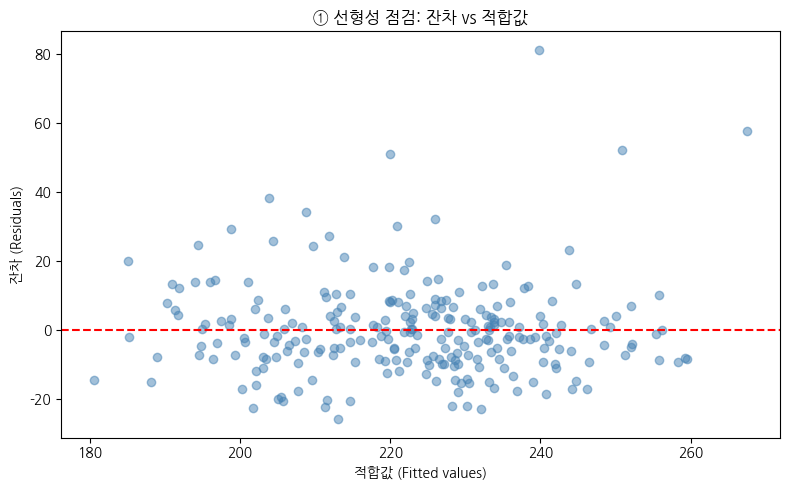

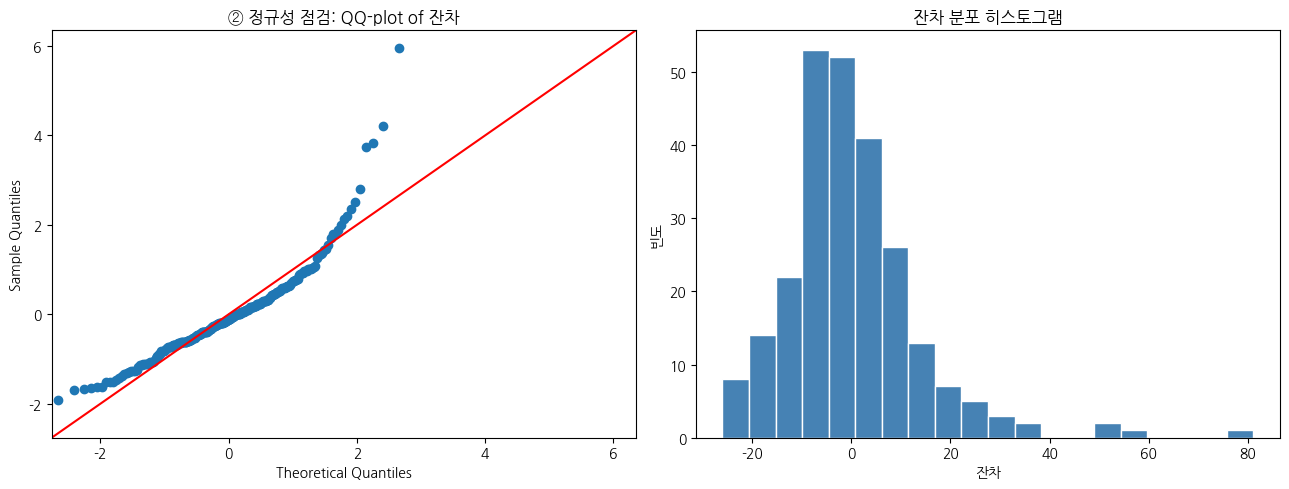


[정규성] Shapiro-Wilk: stat=0.8883, p=0.0000
  → 정규성 위배 ✗

[독립성] Durbin-Watson = 2.0737
  → 잔차 독립성 만족 ✓

[등분산성] Breusch-Pagan 검정
  LM 통계량: 1.8142
  LM p-value: 0.6118
  F 통계량: 0.5994
  F p-value: 0.6160
  → 등분산성 만족 ✓


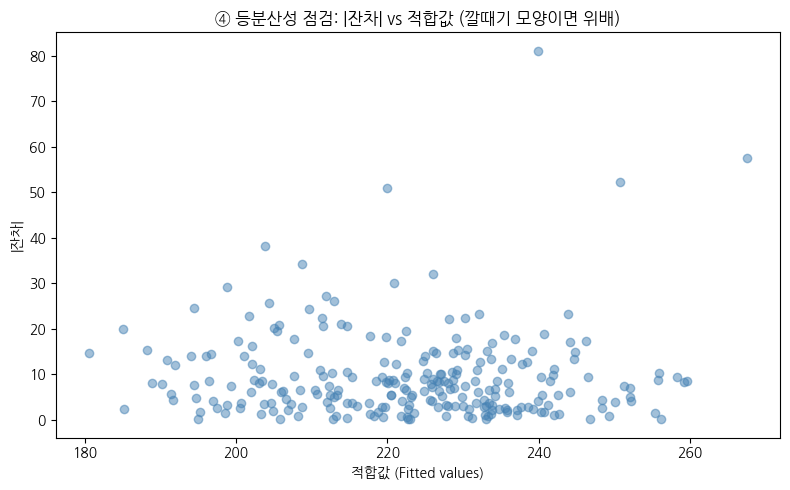


  회귀 진단 종합 결과
① 선형성     : 잔차 vs 적합값 산점도로 시각 확인
② 정규성     : Shapiro-Wilk p = 0.0000 ✗
③ 독립성     : Durbin-Watson  = 2.0737 ✓
④ 등분산성   : Breusch-Pagan p = 0.6118 ✓


In [ ]:
# ============================================================
# 회귀 진단 (Regression Diagnostics) — 4가지 가정 점검
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib                       # 한글 폰트
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats

# === 0. 회귀모형 적합 (예시) ===========================================
df = pd.read_csv('week13_health.csv', encoding='cp949')
model = smf.ols('콜레스테롤 ~ 나이 + BMI + 혈압', data=df).fit()
print(model.summary())

# 잔차와 적합값 추출
resid    = model.resid          # 잔차 (y - ŷ)
fitted   = model.fittedvalues   # 적합값 (ŷ)


# === 1. 선형성 (Linearity) ============================================
#    잔차 vs 적합값 산점도 — 무작위로 흩어져야 정상
#    U자/곡선 패턴 보이면 선형성 위배
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted, resid, alpha=0.5, color='steelblue')
ax.axhline(0, color='red', linestyle='--', lw=1.5)
ax.set_xlabel('적합값 (Fitted values)')
ax.set_ylabel('잔차 (Residuals)')
ax.set_title('① 선형성 점검: 잔차 vs 적합값')
plt.tight_layout(); plt.show()


# === 2. 정규성 (Normality) ============================================
#    잔차의 QQ-plot + Shapiro-Wilk 검정
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 2-1) QQ-plot
sm.qqplot(resid, line='45', fit=True, ax=axes[0])
axes[0].set_title('② 정규성 점검: QQ-plot of 잔차')

# 2-2) 잔차 히스토그램 (참고용)
axes[1].hist(resid, bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel('잔차'); axes[1].set_ylabel('빈도')
axes[1].set_title('잔차 분포 히스토그램')
plt.tight_layout(); plt.show()

# 2-3) Shapiro-Wilk 검정 (p > 0.05이면 정규성 만족)
stat, p_norm = stats.shapiro(resid)
print(f"\n[정규성] Shapiro-Wilk: stat={stat:.4f}, p={p_norm:.4f}")
print("  → " + ("정규성 만족 ✓" if p_norm > 0.05 else "정규성 위배 ✗"))


# === 3. 독립성 (Independence) ==========================================
#    Durbin-Watson 통계량 — 1.5 ~ 2.5 사이면 정상
dw = durbin_watson(resid)
print(f"\n[독립성] Durbin-Watson = {dw:.4f}")
if 1.5 <= dw <= 2.5:
    print("  → 잔차 독립성 만족 ✓")
elif dw < 1.5:
    print("  → 양의 자기상관 의심 ✗")
else:
    print("  → 음의 자기상관 의심 ✗")


# === 4. 등분산성 (Homoscedasticity) ====================================
#    Breusch-Pagan 검정 — p > 0.05이면 등분산성 만족
bp_test = het_breuschpagan(resid, model.model.exog)
labels = ['LM 통계량', 'LM p-value', 'F 통계량', 'F p-value']
bp_result = dict(zip(labels, bp_test))
print(f"\n[등분산성] Breusch-Pagan 검정")
for k, v in bp_result.items():
    print(f"  {k}: {v:.4f}")
print("  → " + ("등분산성 만족 ✓" if bp_result['LM p-value'] > 0.05
                else "이분산성 의심 ✗"))

# 시각적 확인: 잔차의 절댓값 vs 적합값
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted, np.abs(resid), alpha=0.5, color='steelblue')
ax.set_xlabel('적합값 (Fitted values)')
ax.set_ylabel('|잔차|')
ax.set_title('④ 등분산성 점검: |잔차| vs 적합값 (깔때기 모양이면 위배)')
plt.tight_layout(); plt.show()


# === 종합 요약 출력 ====================================================
print("\n" + "="*50)
print("  회귀 진단 종합 결과")
print("="*50)
print(f"① 선형성     : 잔차 vs 적합값 산점도로 시각 확인")
print(f"② 정규성     : Shapiro-Wilk p = {p_norm:.4f} "
      f"{'✓' if p_norm > 0.05 else '✗'}")
print(f"③ 독립성     : Durbin-Watson  = {dw:.4f} "
      f"{'✓' if 1.5 <= dw <= 2.5 else '✗'}")
print(f"④ 등분산성   : Breusch-Pagan p = {bp_result['LM p-value']:.4f} "
      f"{'✓' if bp_result['LM p-value'] > 0.05 else '✗'}")